In [ ]:
# ===== 0. 설정 (커널 재시작하면 이것부터 실행) =====
import torch, cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO

DEVICE   = 0 if torch.cuda.is_available() else "cpu"
SEG_ROOT = Path("PKLot/PKLotSegmented")
DATA_DIR = Path("datasets/pklot_cls")
BEST_PT  = "runs/classify/runs/cls_v1/weights/best.pt"

best = YOLO(BEST_PT)
print("device:", DEVICE, "| classes:", best.names)
print("device:", DEVICE)

c:\Users\inje0329\anaconda3\envs\yolo-smartPKLot\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: 0 | classes: {0: 'empty', 1: 'occupied'}
device: 0


In [ ]:

# 장치 선택: NVIDIA GPU면 0, 맥(M칩)이면 "mps", 둘 다 없으면 "cpu"
DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

model = YOLO("yolo26n-cls.pt")        # ImageNet으로 사전학습된 가장 작은 분류 모델

results = model.train(
    data=str(DATA_DIR),   # 폴더 경로만 주면 train/val을 알아서 찾음
    epochs=10,            # 첫 실험이라 짧게
    imgsz=96,             # 크롭이 작아서(40~100px) 96이면 충분
    batch=128,            # 메모리 부족 에러가 나면 64, 32로 줄이기
    device=DEVICE,
    workers=2,            # 노트북/주피터에서는 작게 두는 게 안전
    project="runs", name="cls_v1",
)
print("best 가중치:", model.trainer.best)

Ultralytics 8.4.171  Python-3.11.16 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX A6000, 49140MiB)
YOLO26n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: C:\Users\inje0329\Desktop\-yolo\yolo_SamartPKLot-main\datasets\pklot_cls\train... found 227868 images in 2 classes  
val: C:\Users\inje0329\Desktop\-yolo\yolo_SamartPKLot-main\datasets\pklot_cls\val... found 43760 images in 2 classes  
test: C:\Users\inje0329\Desktop\-yolo\yolo_SamartPKLot-main\datasets\pklot_cls\test... found 424223 images in 2 classes  
test: Fast image access  (ping: 0.10.0 ms, read: 5.41.5 MB/s, size: 1.1 KB)
test: Scanning C:\Users\inje0329\Desktop\송우진-yolo\yolo_SamartPKLot-main\datasets\pklot_cls\test... 424223 images, 0 corrupt: 100% ━━━━━━━━━━━━ 424223/424223 2.8Kit/s 2:310.1ss
test: New cache created: C:\Users\inje0329\Desktop\-yolo\yolo_SamartPKLot-main\datasets\pklot_cls\test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 26514/26514 75.6it/s 5:51<0.1ss
 

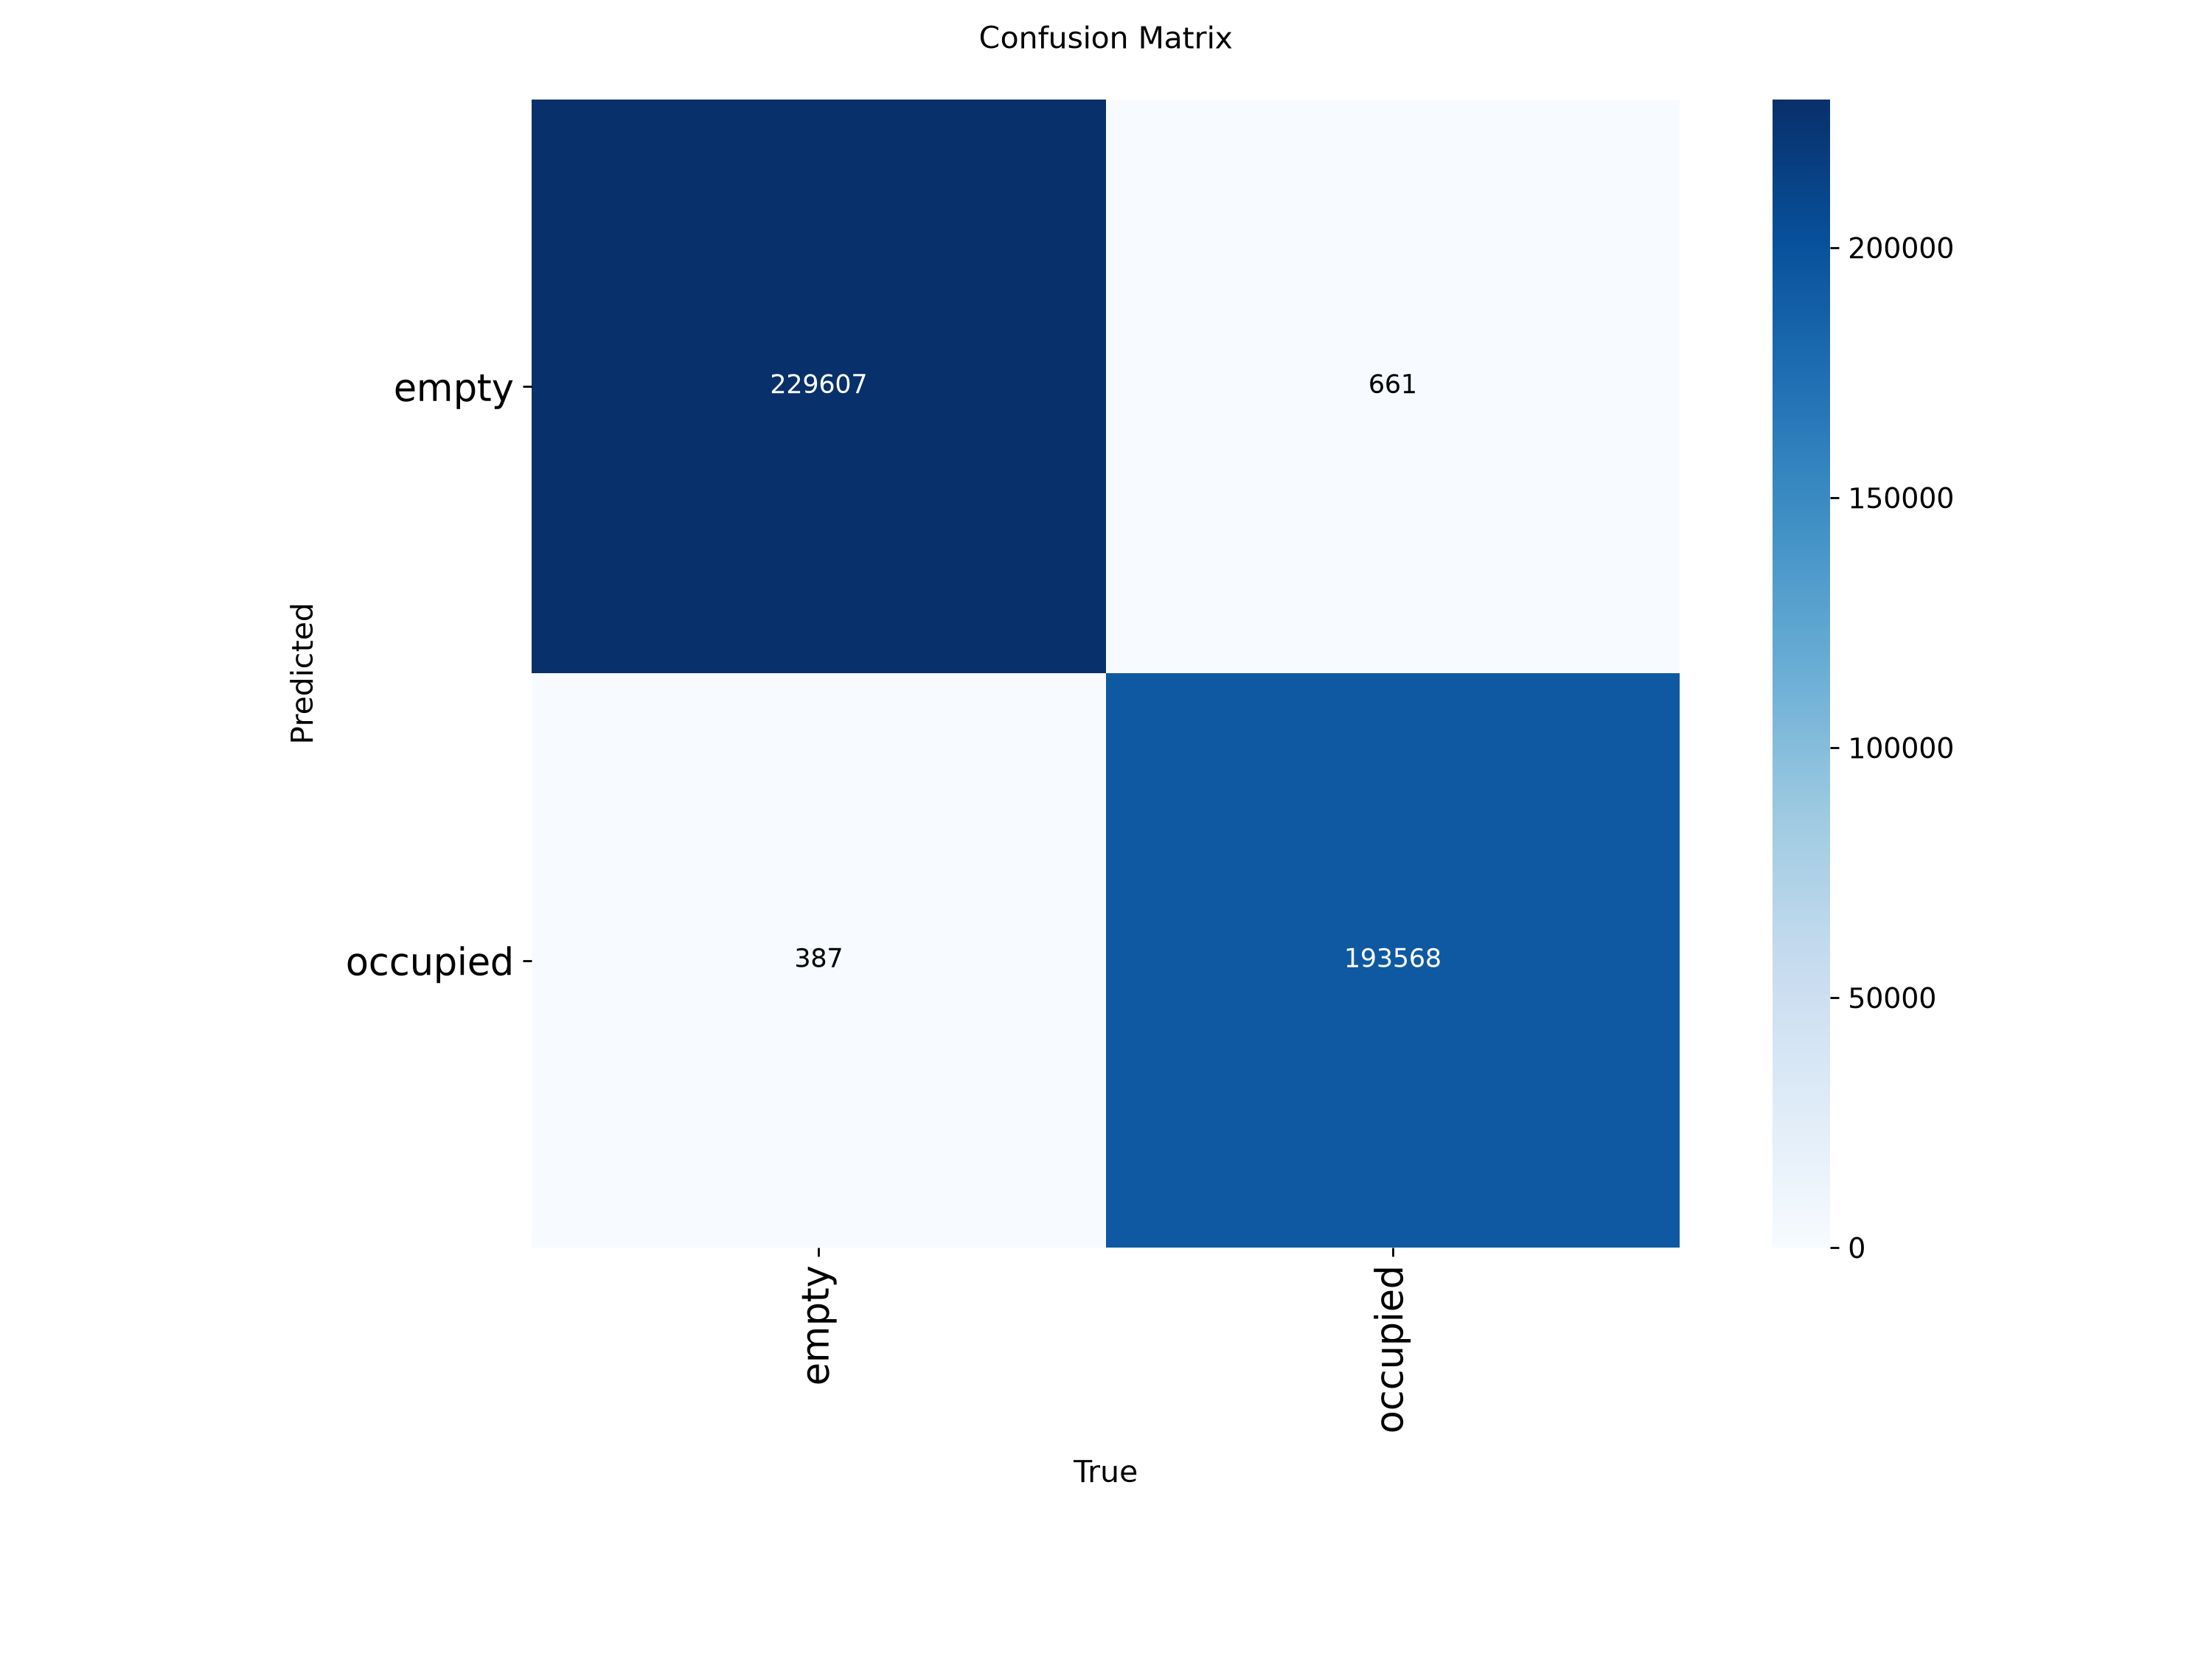

In [2]:
DATA_DIR = Path("datasets/pklot_cls")
metrics = best.val(data=str(DATA_DIR), split="test", imgsz=96, device=DEVICE)
print("test 정확도 (처음 보는 주차장):", metrics.top1)

from IPython.display import Image as IPImage
display(IPImage(str(Path(metrics.save_dir) / "confusion_matrix.png"), width=450))